In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("No GPU detected")

PyTorch version: 2.11.0+cu128
GPU available: True
GPU: Tesla T4


In [ ]:
!pip install -U diffusers transformers accelerate safetensors

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.3/12.3 MB 66.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 394.3/394.3 kB 34.0 MB/s eta 0:00:00
  Attempting uninstall: transformers
    Found existing installation: transformers 5.16.1
    Uninstalling transformers-5.16.1:
      Successfully uninstalled transformers-5.16.1
  Attempting uninstall: accelerate
    Found existing installation: accelerate 1.14.0
    Uninstalling accelerate-1.14.0:
      Successfully uninstalled accelerate-1.14.0


Loading Pretrained Image Generation Model

In [ ]:
import torch
from diffusers import DiffusionPipeline

model_id = "segmind/tiny-sd"

device = "cuda" if torch.cuda.is_available() else "cpu"

pipe = DiffusionPipeline.from_pretrained(
    model_id,
    torch_dtype=torch.float16 if device == "cuda" else torch.float32
)

pipe = pipe.to(device)

print("Pre-trained image generation model loaded successfully!")
print("Model:", model_id)
print("Device:", device)

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/584 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 12 files:   0%|          | 0/12 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

An error occurred while trying to fetch /root/.cache/huggingface/hub/models--segmind--tiny-sd/snapshots/cad0bd7495fa6c4bcca01b19a723dc91627fe84f/unet: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--segmind--tiny-sd/snapshots/cad0bd7495fa6c4bcca01b19a723dc91627fe84f/unet.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.


Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

An error occurred while trying to fetch /root/.cache/huggingface/hub/models--segmind--tiny-sd/snapshots/cad0bd7495fa6c4bcca01b19a723dc91627fe84f/vae: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--segmind--tiny-sd/snapshots/cad0bd7495fa6c4bcca01b19a723dc91627fe84f/vae.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.


Pre-trained image generation model loaded successfully!
Model: segmind/tiny-sd
Device: cuda


  0%|          | 0/30 [00:00<?, ?it/s]

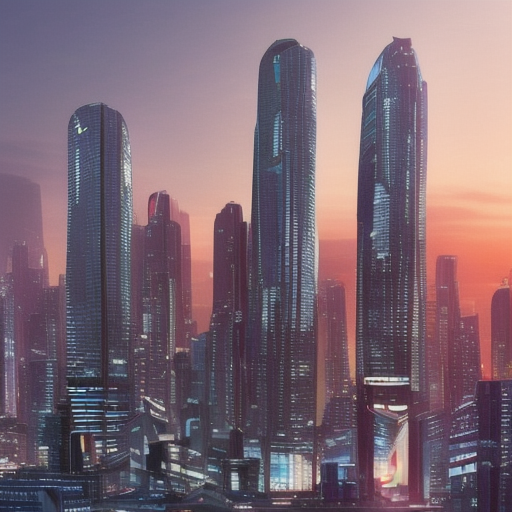

In [ ]:
prompt = "A futuristic city at sunset, flying cars, tall glass buildings, cinematic lighting, highly detailed"

image = pipe(
    prompt,
    num_inference_steps=30,
    guidance_scale=7.5
).images[0]

display(image)

In [ ]:
image.save("generated_city.png")

print("Image saved successfully!")
print("File: generated_city.png")

Image saved successfully!
File: generated_city.png


  0%|          | 0/30 [00:00<?, ?it/s]

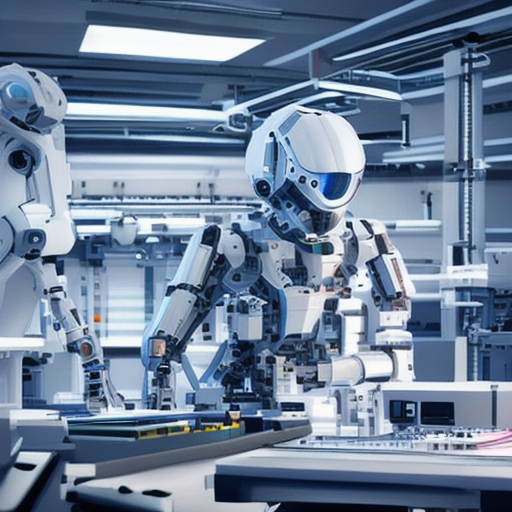

In [ ]:
prompt2 = "A young engineer working on a futuristic robot in a modern laboratory, computer screens, advanced technology, cinematic lighting, detailed digital art"

image2 = pipe(
    prompt2,
    num_inference_steps=30,
    guidance_scale=7.5
).images[0]

display(image2)

In [ ]:
image2.save("generated_engineer.png")

print("Second image saved successfully!")
print("File: generated_engineer.png")

Second image saved successfully!
File: generated_engineer.png


README.md

In [ ]:
readme_task2 = """
# PRODIGY_GA_02 - Image Generation with Pre-trained Models

## Objective
Generate images from text prompts using a pre-trained generative AI model.

## Model Used
- Model: Segmind Tiny-SD
- Framework: Hugging Face Diffusers
- Hardware: Google Colab NVIDIA Tesla T4 GPU

## Technologies Used
- Python
- PyTorch
- Hugging Face Diffusers
- Hugging Face Transformers
- Accelerate
- Safetensors

## Method
The pre-trained text-to-image model was loaded using the DiffusionPipeline.
Text prompts were provided to the model, which generated images based on the
description.

## Image Generation Examples

### Example 1
Prompt:
"A futuristic city at sunset, flying cars, tall glass buildings, cinematic lighting, highly detailed"

Output:
`generated_city.png`

### Example 2
Prompt:
"A young engineer working on a futuristic robot in a modern laboratory, computer screens, advanced technology, cinematic lighting, detailed digital art"

Output:
`generated_engineer.png`

## Generation Settings
- Inference steps: 30
- Guidance scale: 7.5
- Device: CUDA / NVIDIA Tesla T4

## Conclusion
This project demonstrates text-to-image generation using a pre-trained
generative model. Different text prompts were converted into visual images
using the Stable Diffusion-based Tiny-SD model.
"""

with open("README.md", "w", encoding="utf-8") as file:
    file.write(readme_task2)

print("README.md created successfully!")

README.md created successfully!


In [ ]:
import os

required_files = [
    "generated_city.png",
    "generated_engineer.png",
    "README.md"
]

print("TASK-02 FINAL PROJECT CHECK")
print("=" * 50)

for file in required_files:
    if os.path.exists(file):
        print("✅", file)
    else:
        print("❌", file)

print("=" * 50)
print("Task-02 file check completed!")

TASK-02 FINAL PROJECT CHECK
✅ generated_city.png
✅ generated_engineer.png
✅ README.md
Task-02 file check completed!
